In [4]:
from google.colab import files
uploaded = files.upload()

Saving SNLS80mV.mat to SNLS80mV.mat


In [7]:
import numpy as np
import scipy.io
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [10]:
# 1. Data Loading & Preprocessing
# -------------------------------
# Load MATLAB file
mat = scipy.io.loadmat('SNLS80mV.mat')

V1 = mat['V1'].flatten()
V2 = mat['V2'].flatten()
fs = 610.35
dt = 1.0 / fs

start_idx = 42650
excerpt_len = 4096
u_excerpt = V1[start_idx : start_idx + excerpt_len]
y_excerpt = V2[start_idx : start_idx + excerpt_len]

# Center the signals by subtracting their means
u_centered = u_excerpt - np.mean(u_excerpt)
y_centered = y_excerpt - np.mean(y_excerpt)

v_centered = np.zeros_like(y_centered)
v_centered[1:-1] = (y_centered[2:] - y_centered[:-2]) / (2 * dt)
v_centered[0] = (y_centered[1] - y_centered[0]) / dt
v_centered[-1] = (y_centered[-1] - y_centered[-2]) / dt

u_t = torch.tensor(u_centered, dtype=torch.float32).unsqueeze(1)
y_t = torch.tensor(y_centered, dtype=torch.float32).unsqueeze(1)
v_t = torch.tensor(v_centered, dtype=torch.float32).unsqueeze(1)

In [29]:
# 2. Network & RK4 Integrator
# -------------------------------
class AccelerationNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, y, v, u):
        y_scaled = y * 5.0
        v_scaled = v * 0.01
        u_scaled = u * 5.0

        x = torch.cat([y_scaled, v_scaled, u_scaled], dim=-1)

        return self.net(x) * 40000.0

def rk4_step(model, y, v, u_t, u_next, dt):
    """Classical Runge-Kutta 4th Order step for coupled (y, v) system."""
    u_mid = (u_t + u_next) / 2.0  # Linear interpolation for half-step input

    def get_derivatives(y_, v_, u_):
        return v_, model(y_, v_, u_)

    dy1, dv1 = get_derivatives(y, v, u_t)
    dy2, dv2 = get_derivatives(y + dy1 * dt/2, v + dv1 * dt/2, u_mid)
    dy3, dv3 = get_derivatives(y + dy2 * dt/2, v + dv2 * dt/2, u_mid)
    dy4, dv4 = get_derivatives(y + dy3 * dt, v + dv3 * dt, u_next)

    y_next = y + (dt / 6.0) * (dy1 + 2*dy2 + 2*dy3 + dy4)
    v_next = v + (dt / 6.0) * (dv1 + 2*dv2 + 2*dv3 + dv4)
    return y_next, v_next

def free_run(model, y0, v0, u_seq, dt):
    """Integrates the full sequence autoregressively."""
    y_preds = [y0]
    v_preds = [v0]
    y, v = y0, v0

    for i in range(len(u_seq) - 1):
        y, v = rk4_step(model, y, v, u_seq[i:i+1], u_seq[i+1:i+2], dt)
        y_preds.append(y)
        v_preds.append(v)

    return torch.cat(y_preds), torch.cat(v_preds)

In [30]:
# -------------------------------
# 3. Training Loop
# -------------------------------
model = AccelerationNet()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

epochs = 5000
train_samples = 3072

print("Training started...")
model.train()
for epoch in range(epochs):
    if epoch < 1000:
        rollout_len = 2
    elif epoch < 2500:
        rollout_len = 8
    elif epoch < 4000:
        rollout_len = 32
    else:
        rollout_len = 64

    idx = np.random.randint(0, train_samples - rollout_len)

    y0 = y_t[idx:idx+1]
    v0 = v_t[idx:idx+1]
    u_seq = u_t[idx : idx + rollout_len]
    y_target = y_t[idx : idx + rollout_len]

    y_pred, _ = free_run(model, y0, v0, u_seq, dt)
    loss = nn.functional.mse_loss(y_pred, y_target)

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Rollout: {rollout_len} | MSE Loss: {loss.item():.6f}")

Training started...
Epoch 500/5000 | Rollout: 2 | MSE Loss: 0.000000
Epoch 1000/5000 | Rollout: 2 | MSE Loss: 0.000009
Epoch 1500/5000 | Rollout: 8 | MSE Loss: 0.000003
Epoch 2000/5000 | Rollout: 8 | MSE Loss: 0.000002
Epoch 2500/5000 | Rollout: 8 | MSE Loss: 0.000007
Epoch 3000/5000 | Rollout: 32 | MSE Loss: 0.000018
Epoch 3500/5000 | Rollout: 32 | MSE Loss: 0.000012
Epoch 4000/5000 | Rollout: 32 | MSE Loss: 0.000135
Epoch 4500/5000 | Rollout: 64 | MSE Loss: 0.000089
Epoch 5000/5000 | Rollout: 64 | MSE Loss: 0.000005


In [31]:
# 4. Evaluation & Free Run Metric
# -------------------------------
model.eval()
with torch.no_grad():
    y0_full, v0_full = y_t[0:1], v_t[0:1]
    y_pred_full, _ = free_run(model, y0_full, v0_full, u_t, dt)

    # Split into train and test segments
    y_pred_train = y_pred_full[:train_samples]
    y_target_train = y_t[:train_samples]

    y_pred_test = y_pred_full[train_samples:]
    y_target_test = y_t[train_samples:]

    # Calculate RMSE
    train_rmse = torch.sqrt(torch.mean((y_pred_train - y_target_train)**2)).item()
    test_rmse = torch.sqrt(torch.mean((y_pred_test - y_target_test)**2)).item()
    baseline_rmse = torch.sqrt(torch.mean(y_target_test**2)).item()

print(f"\n--- Results ---")
print(f"Baseline Test RMSE (Predicting Zero): {baseline_rmse:.4f} V")
print(f"Free-Run Train RMSE: {train_rmse:.4f} V")
print(f"Free-Run Test RMSE:  {test_rmse:.4f} V")


--- Results ---
Baseline Test RMSE (Predicting Zero): 0.0605 V
Free-Run Train RMSE: 0.0103 V
Free-Run Test RMSE:  0.0240 V


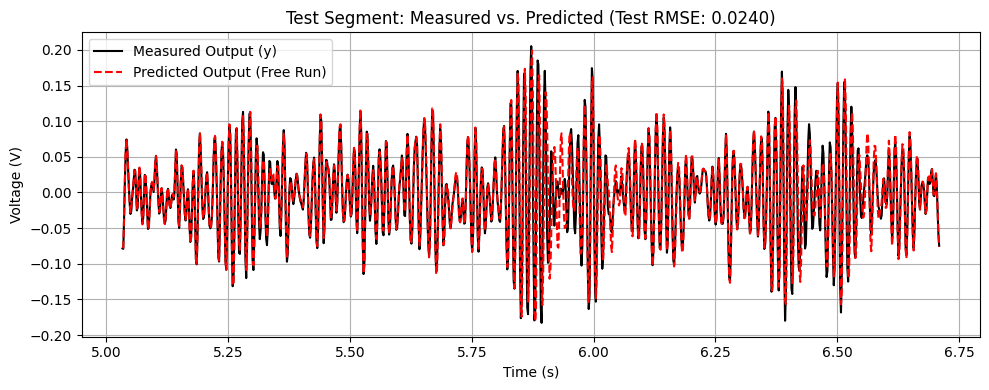

In [32]:
# 5. Plotting
# -------------------------------
time_test = np.arange(train_samples, train_samples + 1024) * dt

plt.figure(figsize=(10, 4))
plt.plot(time_test, y_target_test.numpy(), label='Measured Output (y)', color='black', linewidth=1.5)
plt.plot(time_test, y_pred_test.numpy(), label='Predicted Output (Free Run)', color='red', linestyle='--', linewidth=1.5)
plt.title(f'Test Segment: Measured vs. Predicted (Test RMSE: {test_rmse:.4f})')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()